# Лабораторная работа №2. Классификация. Нейронные сети

**Выполнил:** Ненашкин В. Д., группа АВТ-313.  
**Дисциплина:** «Системы искусственного интеллекта и машинное обучение».

Цель работы: сравнить методы классификации scikit-learn, настроить их параметры и исследовать обучение нейронной сети TensorFlow. Используется ранее выбранный набор Pima Indians Diabetes. Четыре варианта наивного Байеса рассматриваются отдельно; вместе с деревом, LDA, SVM и kNN получаются восемь классификаторов.

Сначала выделяется test. Все параметры выбираются внутри оставшейся обучающей выборки. Метрики на test вычисляются в последнем разделе, когда настройка уже закончена. Дополнительная часть содержит сетку из трёх скоростей обучения и трёх архитектур сети с пятикратной кросс-валидацией.

## 1. Данные и предобработка

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import json
import hashlib
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, make_scorer

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()
LOG_DIR = Path('runtime/logs') / time.strftime('%Y%m%d-%H%M%S')
LOG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', font_scale=1.05)
pd.set_option('display.max_colwidth', 70)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


Seed 42 фиксирует случайные разбиения и начальные веса сетей. Логи каждого запуска сохраняются в отдельном каталоге `runtime/logs`, поэтому повторное выполнение не удаляет прежние логи. Графики и таблицы остаются в выводах ноутбука.

Набор OpenML `diabetes`, версия 1, содержит записи 768 женщин не моложе 21 года из народа пима. Восемь признаков описывают число беременностей, глюкозу, давление, толщину кожной складки, инсулин, индекс массы тела, показатель наследственной предрасположенности и возраст. Положительная метка `tested_positive` кодируется единицей. Это учебная задача по меткам набора.

In [2]:
df = pd.read_csv('diabetes.csv')
df = df.rename(columns={'preg': 'Pregnancies', 'plas': 'Glucose', 'pres': 'BloodPressure',
                        'skin': 'SkinThickness', 'insu': 'Insulin', 'mass': 'BMI',
                        'pedi': 'DiabetesPedigreeFunction', 'age': 'Age', 'class': 'Outcome'})
df['Outcome'] = (df['Outcome'] == 'tested_positive').astype(int)
print('Размер таблицы (строк, столбцов):', df.shape)
display(df.head())
print('SHA-256:', hashlib.sha256(Path('diabetes.csv').read_bytes()).hexdigest())

Размер таблицы (строк, столбцов): (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


SHA-256: de2e5ee67a97714d8cabfad8abe892375fc621feed7e9bf76c11a4ee43f403f6


В таблице 768 строк и девять столбцов: восемь признаков и цель `Outcome`. Класс 1 соответствует исходной метке `tested_positive`, класс 0 соответствует `tested_negative`. Контрольная сумма идентифицирует используемый файл.

In [3]:
print('Пропусков в CSV:', int(df.isna().sum().sum()))
print('Полных повторов строк:', int(df.duplicated().sum()))
balance = df['Outcome'].value_counts().sort_index().to_frame('Объектов')
balance['Доля'] = balance['Объектов'] / len(df)
display(balance)
display(df.describe().T.round(2))

Пропусков в CSV: 0
Полных повторов строк: 0


,Объектов,Доля
Outcome,,
0,500,0.651042
1,268,0.348958


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


В классе 0 находятся 500 объектов, в классе 1 — 268. Постоянный ответ «класс 0» уже даёт около 65% accuracy, поэтому одной accuracy недостаточно. В файле нет пустых ячеек и полных повторов, но некоторые нули требуют отдельной обработки.

In [4]:
ZERO_AS_MISSING = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zeros = (df[ZERO_AS_MISSING] == 0).sum()
display(pd.DataFrame({'Нулей': zeros, 'Доля, %': zeros / len(df) * 100}).round(2))
X = df.drop(columns='Outcome').copy()
y = df['Outcome'].copy()
X[ZERO_AS_MISSING] = X[ZERO_AS_MISSING].mask(X[ZERO_AS_MISSING] == 0)
df_plot = X.assign(Outcome=y)

,Нулей,"Доля, %"
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


Нулевые Glucose, BloodPressure, SkinThickness, Insulin и BMI в этой работе считаются пропусками. Для Insulin таких строк 374, для SkinThickness 227. Число беременностей, равное нулю, остаётся допустимым значением. Медианы для заполнения будут вычисляться только по обучающей части.

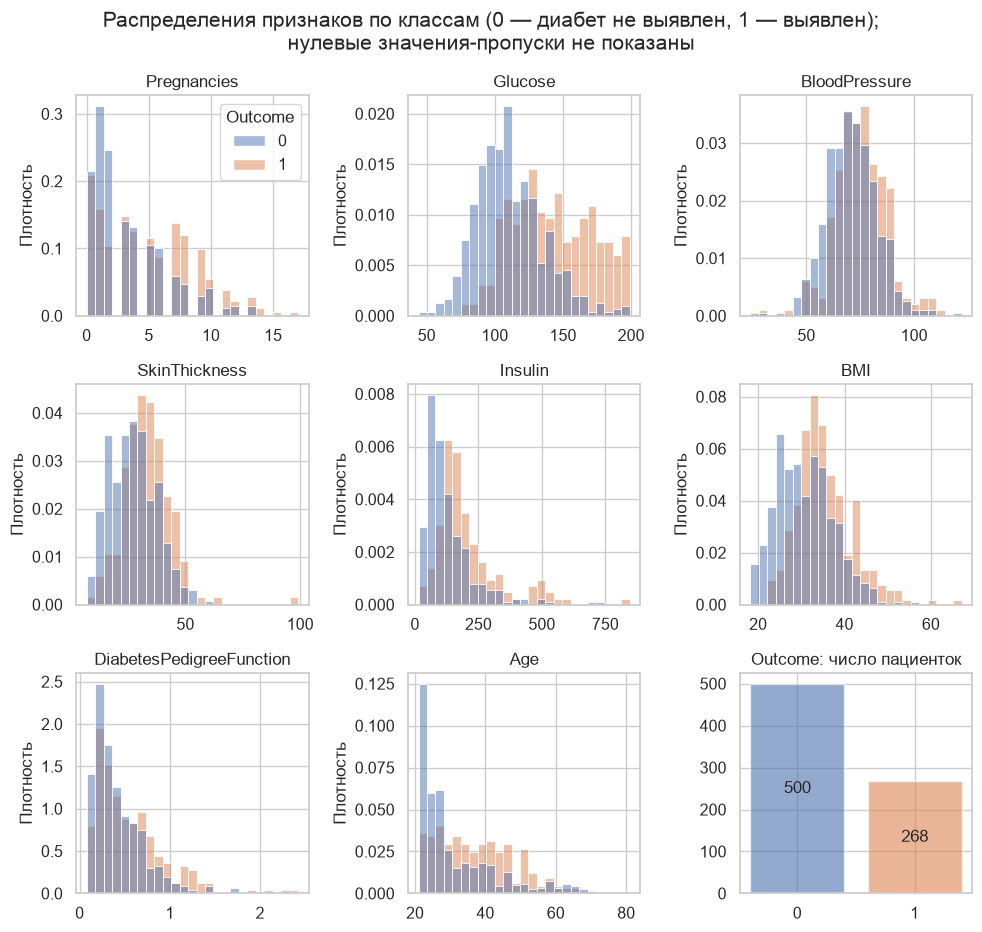

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(10, 9.5))
for ax, col in zip(axes.ravel(), df.columns[:-1]):
    sns.histplot(data=df_plot, x=col, hue='Outcome', stat='density', common_norm=False,
                 bins=25, alpha=0.5, legend=(col == df.columns[0]), ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Плотность')
class_counts = df['Outcome'].value_counts().sort_index()
bars = axes[2, 2].bar(['0', '1'], class_counts.values, color=sns.color_palette()[:2], alpha=0.6)
axes[2, 2].bar_label(bars, label_type='center')
axes[2, 2].set_title('Outcome: число пациенток')
fig.suptitle('Распределения признаков по классам (0 — диабет не выявлен, 1 — выявлен);\n'
             'нулевые значения-пропуски не показаны')
fig.tight_layout()
plt.show()

Распределения признаков различаются по масштабу и асимметрии. У части значений видны длинные правые хвосты. Диапазоны классов перекрываются, поэтому один порог по одному признаку не разделяет все объекты.

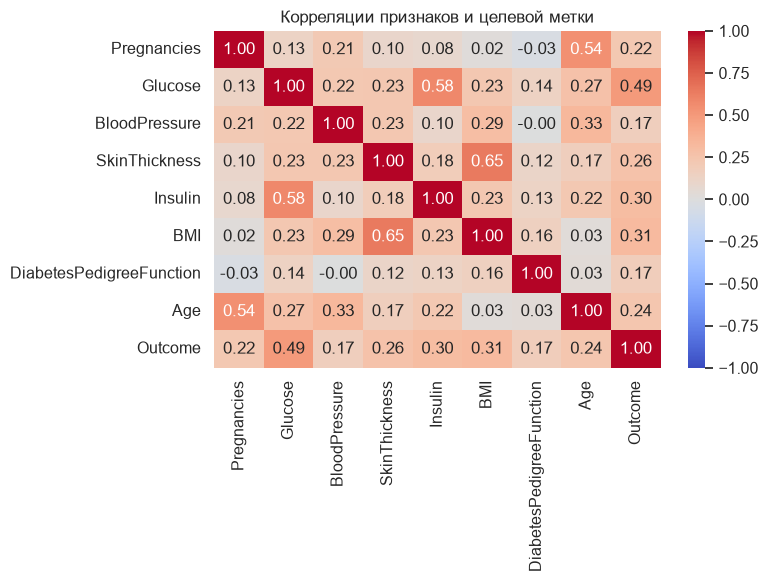

In [6]:
corr = df_plot.corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Корреляции признаков и целевой метки')
plt.tight_layout()
plt.show()

Корреляции описывают связи в этой выборке и не устанавливают причины заболевания. Матрица рассчитана по всем наблюдениям; для проверки условной независимости признаков наивного Байеса потребовался бы отдельный анализ внутри каждого класса.

## 2. Разбиение и критерии сравнения

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

split_table = pd.DataFrame({
    'Объектов': [len(y), len(y_train), len(y_test)],
    'Класс 0': [int((y == 0).sum()), int((y_train == 0).sum()), int((y_test == 0).sum())],
    'Класс 1': [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
    'Доля класса 1': [y.mean(), y_train.mean(), y_test.mean()],
}, index=['Вся выборка', 'Обучающая (train)', 'Тестовая (test)'])
display(split_table.round(3))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

,Объектов,Класс 0,Класс 1,Доля класса 1
Вся выборка,768,500,268,0.349
Обучающая (train),614,400,214,0.349
Тестовая (test),154,100,54,0.351


В train 614 объектов, в test 154. Стратификация сохраняет близкие доли классов. Пять фолдов `cv` формируются только внутри train и одинаковы для всех классических моделей. Критерий выбора их параметров задаётся заранее: средний ROC-AUC на валидационных фолдах.

In [8]:
def make_pipe(model, scaling='standard'):
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scaling == 'standard':
        steps.append(('scaler', StandardScaler()))
    elif scaling == 'minmax':
        steps.append(('scaler', MinMaxScaler(clip=True)))
    steps.append(('clf', model))
    return Pipeline(steps)

metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
scoring = {'accuracy': 'accuracy', 'precision': make_scorer(precision_score, zero_division=0), 'recall': make_scorer(recall_score, zero_division=0), 'f1': make_scorer(f1_score, zero_division=0), 'roc_auc': 'roc_auc'}
models_default = {
    'GaussianNB': make_pipe(GaussianNB(), 'none'),
    'MultinomialNB': make_pipe(MultinomialNB(), 'minmax'),
    'ComplementNB': make_pipe(ComplementNB(), 'minmax'),
    'BernoulliNB': make_pipe(BernoulliNB(binarize=0.0)),
    'Decision Tree': make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), 'none'),
    'LDA': make_pipe(LinearDiscriminantAnalysis()),
    'SVM': make_pipe(SVC()),
    'kNN': make_pipe(KNeighborsClassifier()),
}

Pipeline обучает заполнение пропусков и масштабирование заново в каждом фолде. Для MultinomialNB и ComplementNB нужен неотрицательный вход: `MinMaxScaler(clip=True)` сохраняет диапазон [0, 1] и для новых объектов. Эти два метода исходно рассчитаны на счётчики; здесь они сравниваются как варианты задания. Наивный Байес использует теорему Байеса и предполагает условную независимость признаков при известном классе. GaussianNB описывает непрерывные признаки нормальными распределениями внутри классов. BernoulliNB использует бинарные признаки: после стандартизации порог 0 отделяет значения выше среднего по train.

Accuracy показывает долю верных ответов. Precision, recall и F1 считаются для положительного класса 1 (`average='binary'`). ROC-AUC использует непрерывную оценку класса: вероятность либо `decision_function` у SVM.

## 3. Модели с исходными параметрами

In [9]:
default_rows = []
for name, model in models_default.items():
    values = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    default_rows.append({'Модель': name, **{metric: values['test_' + metric].mean() for metric in metrics}})
default_cv = pd.DataFrame(default_rows).set_index('Модель')
display(default_cv.round(4))

,accuracy,precision,recall,f1,roc_auc
Модель,,,,,
GaussianNB,0.7623,0.6859,0.5984,0.6369,0.8281
MultinomialNB,0.6515,0.0000,0.0000,0.0000,0.7222
ComplementNB,0.6791,0.5333,0.6355,0.5798,0.7222
BernoulliNB,0.7231,0.6023,0.6219,0.6092,0.7848
Decision Tree,0.6726,0.5306,0.5795,0.5519,0.6510
LDA,0.7866,0.7579,0.5748,0.6529,0.8431
SVM,0.7801,0.7415,0.5842,0.6485,0.8333
kNN,0.7296,0.6367,0.5654,0.5939,0.7843


Среди исходных классических моделей наибольший CV ROC-AUC у LDA (0,843), наименьший у дерева (0,651). Из четырёх вариантов Байеса лучший результат у GaussianNB (0,828). MultinomialNB не предсказывает класс 1 на проверочных фолдах: precision, recall и F1 равны нулю, а accuracy 0,651 соответствует доле большинства.

## 4. Настройка гиперпараметров

Каждый поиск использует те же пять фолдов и выбирает максимум среднего ROC-AUC. Значение best_score_ получено при подборе параметров; отдельная test-проверка будет в конце.

In [10]:
searches = {}

def show_search(grid, parameter, log_scale=False):
    table = pd.DataFrame(grid.cv_results_)
    curve = table.groupby('param_clf__' + parameter, dropna=False)[['mean_train_score', 'mean_test_score']].mean()
    curve.columns = ['Train ROC-AUC', 'CV ROC-AUC']
    display(curve.round(4))
    ax = curve.plot(marker='o', figsize=(7, 3.4), logx=log_scale)
    ax.set_xlabel(parameter)
    ax.set_ylabel('ROC-AUC')
    plt.tight_layout()
    plt.show()

Для параметра на графике показано среднее по остальным комбинациям сетки. Такой график помогает увидеть общую тенденцию; лучшая совместная комбинация выбирается по полной таблице, а не по отдельным средним.

### 4.1. GaussianNB

var_smoothing задаёт добавку к дисперсиям GaussianNB. Слишком сильное сглаживание может уменьшать различия между классами.

In [11]:
grid = GridSearchCV(models_default['GaussianNB'], param_grid={'clf__var_smoothing': np.logspace(-12, 0, 13)}, scoring='roc_auc', cv=cv, return_train_score=True, n_jobs=1, error_score='raise')
grid.fit(X_train, y_train)
searches['GaussianNB'] = grid
print('Параметры:', grid.best_params_)
print('CV ROC-AUC:', round(grid.best_score_, 4))
display(pd.DataFrame(grid.cv_results_)[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(5))

Параметры: {'clf__var_smoothing': np.float64(1e-06)}
CV ROC-AUC: 0.8288


,params,mean_train_score,mean_test_score,std_test_score
6,{'clf__var_smoothing': 1e-06},0.833365,0.828833,0.008753
5,{'clf__var_smoothing': 1e-07},0.833395,0.828303,0.009201
4,{'clf__var_smoothing': 1e-08},0.833354,0.828187,0.009523
0,{'clf__var_smoothing': 1e-12},0.833347,0.828128,0.009599
1,{'clf__var_smoothing': 1e-11},0.833347,0.828128,0.009599


Выбран var_smoothing = $10^{-6}$: CV ROC-AUC 0,8288 против 0,8281 по умолчанию. Изменение мало относительно самой метрики. На этом наборе настройка сглаживания почти не улучшила GaussianNB.

,Train ROC-AUC,CV ROC-AUC
param_clf__var_smoothing,,
1.000000e-12,0.8333,0.8281
1.000000e-11,0.8333,0.8281
1.000000e-10,0.8333,0.8281
1.000000e-09,0.8333,0.8281
1.000000e-08,0.8334,0.8282
1.000000e-07,0.8334,0.8283
1.000000e-06,0.8334,0.8288
1.000000e-05,0.8326,0.8279
1.000000e-04,0.8289,0.8237


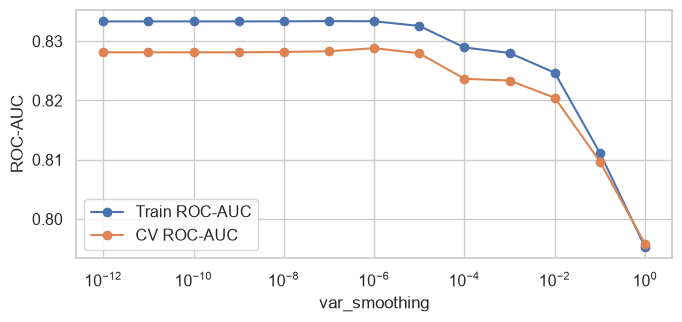

In [12]:
show_search(searches['GaussianNB'], 'var_smoothing', log_scale=True)

При var_smoothing от $10^{-12}$ до $10^{-8}$ CV ROC-AUC после округления остаётся около 0,828. При увеличении параметра от $10^{-6}$ до 1 оценка снижается с 0,8288 до 0,7958. Сильная добавка к дисперсиям ухудшает результат в проверенной сетке.

### 4.2. MultinomialNB

У MultinomialNB alpha сглаживает оценки вероятностей, fit_prior определяет использование частот классов. Рассматриваются их совместные комбинации.

In [13]:
grid = GridSearchCV(models_default['MultinomialNB'], param_grid={'clf__alpha': [0.01, 0.1, 1, 10], 'clf__fit_prior': [True, False]}, scoring='roc_auc', cv=cv, return_train_score=True, n_jobs=1, error_score='raise')
grid.fit(X_train, y_train)
searches['MultinomialNB'] = grid
print('Параметры:', grid.best_params_)
print('CV ROC-AUC:', round(grid.best_score_, 4))
display(pd.DataFrame(grid.cv_results_)[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(5))

Параметры: {'clf__alpha': 1, 'clf__fit_prior': True}
CV ROC-AUC: 0.7222


,params,mean_train_score,mean_test_score,std_test_score
4,"{'clf__alpha': 1, 'clf__fit_prior': True}",0.732927,0.722225,0.024937
5,"{'clf__alpha': 1, 'clf__fit_prior': False}",0.732927,0.722225,0.024937
0,"{'clf__alpha': 0.01, 'clf__fit_prior': True}",0.732891,0.722216,0.024796
1,"{'clf__alpha': 0.01, 'clf__fit_prior': False}",0.732891,0.722216,0.024796
2,"{'clf__alpha': 0.1, 'clf__fit_prior': True}",0.732946,0.722100,0.024750


Выбраны alpha = 1 и fit_prior = True. CV ROC-AUC 0,7222 совпал с исходной настройкой. Наличие пяти метрик в предыдущем сравнении помогает заметить, что приемлемый ROC-AUC не гарантирует полезных решений при стандартном пороге.

,Train ROC-AUC,CV ROC-AUC
param_clf__alpha,,
0.01,0.7329,0.7222
0.10,0.7329,0.7221
1.00,0.7329,0.7222
10.00,0.7309,0.7219


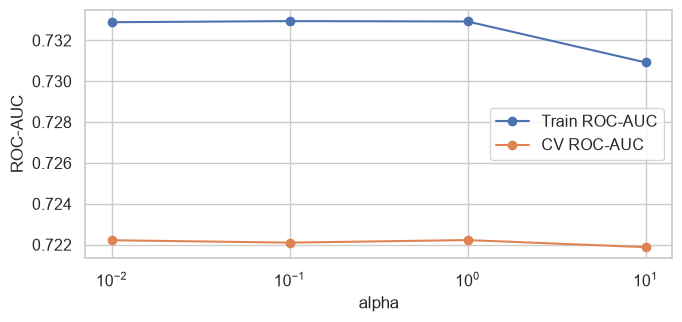

In [14]:
show_search(searches['MultinomialNB'], 'alpha', log_scale=True)

Во всей сетке alpha усреднённый CV ROC-AUC меняется лишь от 0,7219 до 0,7222. Большого изменения качества здесь нет. Значения alpha = 0,01 и alpha = 1 после округления выглядят одинаково; GridSearchCV сравнивает исходные, неокруглённые оценки.

### 4.3. ComplementNB

Для ComplementNB проверяются сглаживание alpha и дополнительная нормализация весов norm.

In [15]:
grid = GridSearchCV(models_default['ComplementNB'], param_grid={'clf__alpha': [0.01, 0.1, 1, 10], 'clf__norm': [False, True]}, scoring='roc_auc', cv=cv, return_train_score=True, n_jobs=1, error_score='raise')
grid.fit(X_train, y_train)
searches['ComplementNB'] = grid
print('Параметры:', grid.best_params_)
print('CV ROC-AUC:', round(grid.best_score_, 4))
display(pd.DataFrame(grid.cv_results_)[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(5))

Параметры: {'clf__alpha': 1, 'clf__norm': False}
CV ROC-AUC: 0.7222


,params,mean_train_score,mean_test_score,std_test_score
4,"{'clf__alpha': 1, 'clf__norm': False}",0.732927,0.722225,0.024937
0,"{'clf__alpha': 0.01, 'clf__norm': False}",0.732891,0.722216,0.024796
2,"{'clf__alpha': 0.1, 'clf__norm': False}",0.732946,0.722100,0.024750
6,"{'clf__alpha': 10, 'clf__norm': False}",0.730923,0.721878,0.024457
1,"{'clf__alpha': 0.01, 'clf__norm': True}",0.711070,0.699396,0.031781


Для ComplementNB выбраны alpha = 1 и norm = False. Его CV ROC-AUC равен 0,7222 и не улучшился после поиска. Параметры и предсказанные классы у ComplementNB и MultinomialNB могут различаться даже при одинаковом ранжировании объектов.

,Train ROC-AUC,CV ROC-AUC
param_clf__alpha,,
0.01,0.7220,0.7108
0.10,0.7220,0.7105
1.00,0.7214,0.7102
10.00,0.7150,0.7042


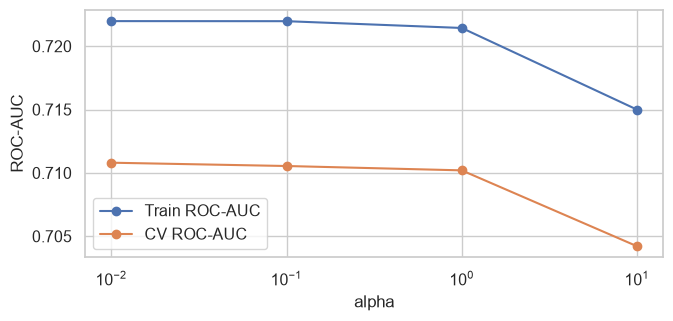

In [16]:
show_search(searches['ComplementNB'], 'alpha', log_scale=True)

График усредняет результат по двум значениям norm. При alpha = 0,01 средний CV ROC-AUC равен 0,7108, при alpha = 10 — 0,7042. Эти средние ниже 0,7222 лучшей совместной комбинации: влияние нормализации нельзя исключать из сравнения.

### 4.4. BernoulliNB

BernoulliNB теряет информацию о величине признака после бинаризации. Проверяются порог binarize, сглаживание alpha и априорные вероятности.

In [17]:
grid = GridSearchCV(models_default['BernoulliNB'], param_grid={'clf__alpha': [0.1, 1, 10], 'clf__binarize': [0, 0.5, 1], 'clf__fit_prior': [True, False]}, scoring='roc_auc', cv=cv, return_train_score=True, n_jobs=1, error_score='raise')
grid.fit(X_train, y_train)
searches['BernoulliNB'] = grid
print('Параметры:', grid.best_params_)
print('CV ROC-AUC:', round(grid.best_score_, 4))
display(pd.DataFrame(grid.cv_results_)[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(5))

Параметры: {'clf__alpha': 0.1, 'clf__binarize': 0.5, 'clf__fit_prior': True}
CV ROC-AUC: 0.7926


,params,mean_train_score,mean_test_score,std_test_score
9,"{'clf__alpha': 1, 'clf__binarize': 0.5, 'clf__fit_prior': False}",0.793869,0.792598,0.030238
8,"{'clf__alpha': 1, 'clf__binarize': 0.5, 'clf__fit_prior': True}",0.793869,0.792598,0.030238
2,"{'clf__alpha': 0.1, 'clf__binarize': 0.5, 'clf__fit_prior': True}",0.793902,0.792598,0.030238
3,"{'clf__alpha': 0.1, 'clf__binarize': 0.5, 'clf__fit_prior': False}",0.793902,0.792598,0.030238
15,"{'clf__alpha': 10, 'clf__binarize': 0.5, 'clf__fit_prior': False}",0.793336,0.792306,0.030733


Выбраны alpha = 0,1, binarize = 0,5 и fit_prior = True. CV ROC-AUC вырос с 0,7848 до 0,7926. В отличие от GaussianNB, этот вариант сначала заменяет каждый признак бинарным признаком относительно порога.

,Train ROC-AUC,CV ROC-AUC
param_clf__binarize,,
0.0,0.7930,0.7848
0.5,0.7937,0.7925
1.0,0.7754,0.7701


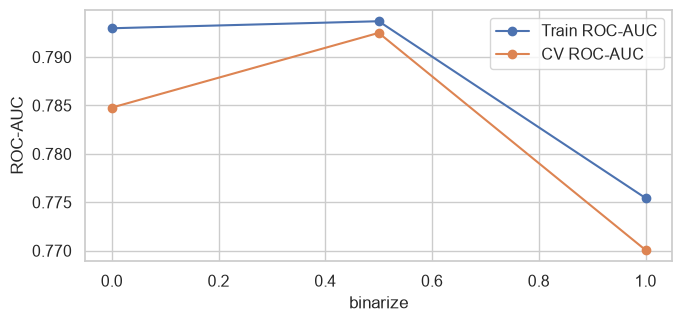

In [18]:
show_search(searches['BernoulliNB'], 'binarize', log_scale=False)

Для binarize = 0,5 средний CV ROC-AUC равен 0,7925, для 0 — 0,7848, для 1 — 0,7701. В проверенной сетке порог 0,5 сохранил более полезное разделение признаков на две группы.

### 4.5. Decision Tree

Дерево последовательно делит объекты по порогам признаков. Критерии Джини и энтропия измеряют смешение классов в узле. У дерева ограничение глубины и размера листа уменьшает сложность модели. Разрыв train и CV помогает заметить переобучение.

In [19]:
grid = GridSearchCV(models_default['Decision Tree'], param_grid={'clf__criterion': ['gini', 'entropy'], 'clf__max_depth': [2, 3, 4, 5, 6, 8, 10, None], 'clf__min_samples_leaf': [1, 5, 10, 20, 30]}, scoring='roc_auc', cv=cv, return_train_score=True, n_jobs=1, error_score='raise')
grid.fit(X_train, y_train)
searches['Decision Tree'] = grid
print('Параметры:', grid.best_params_)
print('CV ROC-AUC:', round(grid.best_score_, 4))
display(pd.DataFrame(grid.cv_results_)[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(5))

Параметры: {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_leaf': 30}
CV ROC-AUC: 0.8055


,params,mean_train_score,mean_test_score,std_test_score
59,"{'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_sampl...",0.875904,0.805494,0.031541
74,"{'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samp...",0.878029,0.805378,0.031443
64,"{'clf__criterion': 'entropy', 'clf__max_depth': 6, 'clf__min_sampl...",0.878029,0.805378,0.031443
69,"{'clf__criterion': 'entropy', 'clf__max_depth': 8, 'clf__min_sampl...",0.878029,0.805378,0.031443
79,"{'clf__criterion': 'entropy', 'clf__max_depth': None, 'clf__min_sa...",0.878029,0.805378,0.031443


Лучшее дерево использует entropy, max_depth = 5 и min_samples_leaf = 30. CV ROC-AUC вырос с 0,6510 до 0,8055. Это наибольший прирост среди рассмотренных классических моделей.

,Train ROC-AUC,CV ROC-AUC
param_clf__min_samples_leaf,,
1,0.9172,0.7272
5,0.9013,0.7493
10,0.8871,0.7582
20,0.8694,0.7758
30,0.8594,0.7868


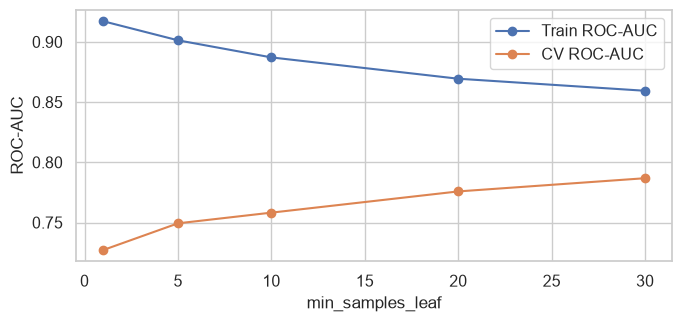

In [20]:
show_search(searches['Decision Tree'], 'min_samples_leaf', log_scale=False)

При увеличении min_samples_leaf от 1 до 30 средний CV ROC-AUC вырос с 0,7272 до 0,7868, а train ROC-AUC снизился с 0,9172 до 0,8594. Разрыв уменьшился: более крупные листья ограничили подстройку к обучающим объектам.

### 4.6. LDA

LDA предполагает общую ковариационную матрицу классов и строит линейную границу между ними. У LDA сравниваются способы решения и регуляризация ковариационной матрицы. Shrinkage не применяется с solver=svd.

In [21]:
grid = GridSearchCV(models_default['LDA'], param_grid=[{'clf__solver': ['svd']}, {'clf__solver': ['lsqr', 'eigen'], 'clf__shrinkage': ['auto', 0, 0.15, 0.3, 0.5, 1]}], scoring='roc_auc', cv=cv, return_train_score=True, n_jobs=1, error_score='raise')
grid.fit(X_train, y_train)
searches['LDA'] = grid
print('Параметры:', grid.best_params_)
print('CV ROC-AUC:', round(grid.best_score_, 4))
display(pd.DataFrame(grid.cv_results_)[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(5))

Параметры: {'clf__shrinkage': 0.15, 'clf__solver': 'lsqr'}
CV ROC-AUC: 0.845


,params,mean_train_score,mean_test_score,std_test_score
5,"{'clf__shrinkage': 0.15, 'clf__solver': 'lsqr'}",0.851226,0.844976,0.014881
6,"{'clf__shrinkage': 0.15, 'clf__solver': 'eigen'}",0.851226,0.844976,0.014881
7,"{'clf__shrinkage': 0.3, 'clf__solver': 'lsqr'}",0.850248,0.844474,0.012531
8,"{'clf__shrinkage': 0.3, 'clf__solver': 'eigen'}",0.850248,0.844474,0.012531
1,"{'clf__shrinkage': 'auto', 'clf__solver': 'lsqr'}",0.850741,0.844085,0.016592


Выбраны solver = lsqr и shrinkage = 0,15. CV ROC-AUC вырос с 0,8431 до 0,8450. Прирост небольшой; исходная LDA уже давала один из лучших результатов.

### 4.7. SVM

SVM ищет разделяющую границу с широким зазором, допуская ошибки с заданным штрафом. Для SVM исследуются линейное и RBF-ядро. C задаёт штраф за ошибки, gamma влияет на локальность RBF-границы. Для линейного ядра gamma не подбирается.

In [22]:
grid = GridSearchCV(models_default['SVM'], param_grid=[{'clf__kernel': ['linear'], 'clf__C': [0.01, 0.1, 1, 10, 100]}, {'clf__kernel': ['rbf'], 'clf__C': [0.1, 1, 10, 100], 'clf__gamma': [0.001, 0.01, 0.1, 1]}], scoring='roc_auc', cv=cv, return_train_score=True, n_jobs=1, error_score='raise')
grid.fit(X_train, y_train)
searches['SVM'] = grid
print('Параметры:', grid.best_params_)
print('CV ROC-AUC:', round(grid.best_score_, 4))
display(pd.DataFrame(grid.cv_results_)[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(5))

Параметры: {'clf__C': 100, 'clf__gamma': 0.001, 'clf__kernel': 'rbf'}
CV ROC-AUC: 0.8464


,params,mean_train_score,mean_test_score,std_test_score
17,"{'clf__C': 100, 'clf__gamma': 0.001, 'clf__kernel': 'rbf'}",0.856199,0.846379,0.015669
10,"{'clf__C': 1, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}",0.854198,0.846307,0.010591
0,"{'clf__C': 0.01, 'clf__kernel': 'linear'}",0.851450,0.845939,0.011684
14,"{'clf__C': 10, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}",0.868619,0.844953,0.017315
3,"{'clf__C': 10, 'clf__kernel': 'linear'}",0.850181,0.844738,0.016193


Лучший вариант SVM: RBF, C = 100, gamma = 0,001. CV ROC-AUC равен 0,8464 против 0,8333 по умолчанию. В верхних строках таблицы также есть линейное ядро, поэтому преимущество RBF здесь невелико.

### 4.8. kNN

kNN определяет класс по ближайшим обучающим объектам. Параметр p=1 задаёт манхэттенское расстояние, p=2 — евклидово. У kNN проверяются число соседей, веса голосов и расстояние. При weights=distance точность на обучающих объектах завышена: ближайшим соседом объекта оказывается он сам.

In [23]:
grid = GridSearchCV(models_default['kNN'], param_grid={'clf__n_neighbors': list(range(1, 101)), 'clf__weights': ['uniform', 'distance'], 'clf__p': [1, 2]}, scoring='roc_auc', cv=cv, return_train_score=True, n_jobs=1, error_score='raise')
grid.fit(X_train, y_train)
searches['kNN'] = grid
print('Параметры:', grid.best_params_)
print('CV ROC-AUC:', round(grid.best_score_, 4))
display(pd.DataFrame(grid.cv_results_)[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(5))

Параметры: {'clf__n_neighbors': 84, 'clf__p': 2, 'clf__weights': 'distance'}
CV ROC-AUC: 0.8375


,params,mean_train_score,mean_test_score,std_test_score
335,"{'clf__n_neighbors': 84, 'clf__p': 2, 'clf__weights': 'distance'}",1.0,0.837456,0.018121
347,"{'clf__n_neighbors': 87, 'clf__p': 2, 'clf__weights': 'distance'}",1.0,0.837442,0.017820
331,"{'clf__n_neighbors': 83, 'clf__p': 2, 'clf__weights': 'distance'}",1.0,0.837277,0.019726
343,"{'clf__n_neighbors': 86, 'clf__p': 2, 'clf__weights': 'distance'}",1.0,0.837157,0.017937
181,"{'clf__n_neighbors': 46, 'clf__p': 1, 'clf__weights': 'distance'}",1.0,0.836959,0.019822


Выбраны 84 соседа, weights = distance и p = 2. CV ROC-AUC вырос с 0,7843 до 0,8375. Увеличение числа соседей по сравнению с исходным k = 5 улучшило результат на этих фолдах.

,Train ROC-AUC,CV ROC-AUC
param_clf__n_neighbors,,
1,1.0000,0.6612
2,0.9740,0.7246
3,0.9614,0.7575
4,0.9558,0.7808
5,0.9517,0.7851
...,...,...
96,0.9180,0.8307
97,0.9179,0.8311
98,0.9179,0.8305


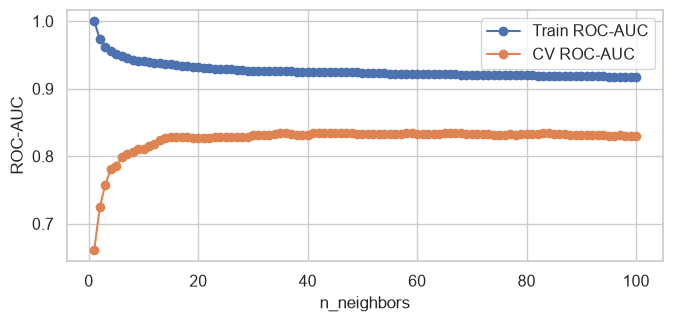

In [24]:
show_search(searches['kNN'], 'n_neighbors', log_scale=False)

При k = 1 усреднённый train ROC-AUC равен 1,0000, а CV ROC-AUC — 0,6612. При k = 100 CV ROC-AUC достигает 0,8299. График показывает сильную зависимость от числа соседей; лучшая полная комбинация найдена при k = 84.

Глубина: 5 | листьев: 11


,Важность
Glucose,0.609536
BMI,0.208712
Age,0.107802
Pregnancies,0.045845
DiabetesPedigreeFunction,0.028104
BloodPressure,0.000000
SkinThickness,0.000000
Insulin,0.000000


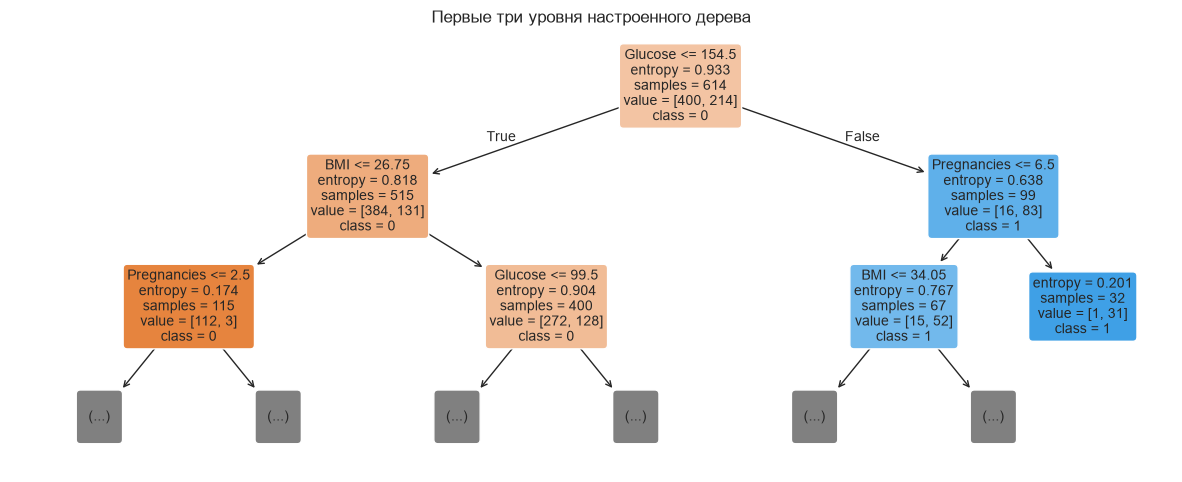

In [25]:
tree = searches['Decision Tree'].best_estimator_.named_steps['clf']
print('Глубина:', tree.get_depth(), '| листьев:', tree.get_n_leaves())
display(pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False).to_frame('Важность'))
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(tree, max_depth=2, feature_names=list(X.columns), class_names=['0', '1'], filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title('Первые три уровня настроенного дерева')
plt.tight_layout()
plt.show()

Фактическая глубина дерева равна 5, число листьев — 11. Наибольшие важности получили Glucose (0,610), BMI (0,209) и Age (0,108). Это характеристики конкретного дерева, а не оценки причинного влияния. На рисунке показаны только первые три уровня.

In [26]:
tuning = pd.DataFrame([{'Модель': name, 'Параметры': str(grid.best_params_), 'ROC-AUC до': default_cv.loc[name, 'roc_auc'], 'ROC-AUC после': grid.best_score_, 'SD после': grid.cv_results_['std_test_score'][grid.best_index_]} for name, grid in searches.items()]).set_index('Модель')
chosen_classic = tuning['ROC-AUC после'].idxmax()
display(tuning.sort_values('ROC-AUC после', ascending=False).round(4))
print('Наибольший CV ROC-AUC среди классических моделей:', chosen_classic)

,Параметры,ROC-AUC до,ROC-AUC после,SD после
Модель,,,,
SVM,"{'clf__C': 100, 'clf__gamma': 0.001, 'clf__kernel': 'rbf'}",0.8333,0.8464,0.0157
LDA,"{'clf__shrinkage': 0.15, 'clf__solver': 'lsqr'}",0.8431,0.8450,0.0149
kNN,"{'clf__n_neighbors': 84, 'clf__p': 2, 'clf__weights': 'distance'}",0.7843,0.8375,0.0181
GaussianNB,{'clf__var_smoothing': np.float64(1e-06)},0.8281,0.8288,0.0088
Decision Tree,"{'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_sampl...",0.6510,0.8055,0.0315
BernoulliNB,"{'clf__alpha': 0.1, 'clf__binarize': 0.5, 'clf__fit_prior': True}",0.7848,0.7926,0.0302
MultinomialNB,"{'clf__alpha': 1, 'clf__fit_prior': True}",0.7222,0.7222,0.0249
ComplementNB,"{'clf__alpha': 1, 'clf__norm': False}",0.7222,0.7222,0.0249


Наибольший CV ROC-AUC среди классических моделей: SVM


Наибольший CV ROC-AUC среди классических моделей у SVM (0,8464), затем LDA (0,8450). Для итогового разбора выбран SVM по заранее заданному критерию. Эти оценки использовались в поиске и могут быть оптимистичными; стандартное отклонение фолдов не доказывает равенство моделей.

## 5. Нейронная сеть TensorFlow

Для отдельных опытов выделим validation из обучающей выборки. Сравним число эпох, размер батча, архитектуру и активацию. Test будет использован в общей итоговой проверке после выбора настроек.

In [27]:
X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

def make_nn_preprocessor():
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

nn_trial_preprocessor = make_nn_preprocessor()
X_nn_train_scaled = nn_trial_preprocessor.fit_transform(X_nn_train).astype('float32')
X_nn_val_scaled = nn_trial_preprocessor.transform(X_nn_val).astype('float32')
print('Обучение сети:', len(y_nn_train), '| validation:', len(y_nn_val))
print('Доли класса 1:', round(y_nn_train.mean(), 3), round(y_nn_val.mean(), 3))

Обучение сети: 491 | validation: 123
Доли класса 1: 0.348 0.35


Внутренняя обучающая часть содержит 491 объект, validation — 123. Доли класса 1 равны 0,348 и 0,350. Импутер и scaler обучены на 491 строке; validation преобразована с теми же параметрами.

In [28]:
def make_nn(architecture=(16, 8), activation='relu', learning_rate=0.001):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    model = tf.keras.Sequential([tf.keras.Input(shape=(X_train.shape[1],))])
    for units in architecture:
        model.add(tf.keras.layers.Dense(units, activation=activation))
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

nn_histories = {}
nn_trial_rows = []

def run_nn_trial(name, architecture=(16, 8), activation='relu', epochs=100, batch_size=32, early_stopping=False):
    model = make_nn(architecture, activation)
    callbacks = [tf.keras.callbacks.TensorBoard(log_dir=str(LOG_DIR / 'fit' / name), update_freq='epoch')]
    if early_stopping:
        callbacks.append(tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True))
    started = time.perf_counter()
    history = model.fit(
        X_nn_train_scaled, y_nn_train, validation_data=(X_nn_val_scaled, y_nn_val),
        epochs=epochs, batch_size=batch_size, callbacks=callbacks, verbose=0
    )
    training_seconds = time.perf_counter() - started
    train_metrics = model.evaluate(X_nn_train_scaled, y_nn_train, verbose=0, return_dict=True)
    val_metrics = model.evaluate(X_nn_val_scaled, y_nn_val, verbose=0, return_dict=True)
    probabilities = model(X_nn_val_scaled, training=False).numpy().ravel()
    nn_histories[name] = history.history
    nn_trial_rows.append({
        'run': name, 'architecture': '-'.join(map(str, architecture)), 'activation': activation,
        'batch_size': batch_size, 'epochs': len(history.history['loss']), 'parameters': model.count_params(),
        'training_seconds': training_seconds,
        'train_loss': train_metrics['loss'], 'val_loss': val_metrics['loss'],
        'train_accuracy': train_metrics['accuracy'], 'val_accuracy': val_metrics['accuracy'],
        'val_roc_auc': roc_auc_score(y_nn_val, probabilities),
        'min_history_val_loss': min(history.history['val_loss']),
        'best_epoch': int(np.argmin(history.history['val_loss'])) + 1
    })
    return pd.DataFrame(nn_trial_rows).tail(1)

def plot_nn_trials(names, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    for index, name in enumerate(names):
        history = nn_histories[name]
        epochs = np.arange(1, len(history['loss']) + 1)
        color = plt.get_cmap('tab10')(index)
        axes[0].plot(epochs, history['loss'], '--', color=color, alpha=0.65)
        axes[0].plot(epochs, history['val_loss'], color=color, label=name)
        axes[1].plot(epochs, history['accuracy'], '--', color=color, alpha=0.65)
        axes[1].plot(epochs, history['val_accuracy'], color=color)
    axes[0].set(xlabel='Эпоха', ylabel='Binary cross-entropy', title='Loss: пунктир train, линия validation')
    axes[1].set(xlabel='Эпоха', ylabel='Accuracy', title='Accuracy: пунктир train, линия validation')
    fig.suptitle(title)
    fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0.17, 1, 0.94))
    plt.show()

print('Базовая архитектура: 16–8, ReLU, Adam(learning_rate=0.001), sigmoid на выходе')
make_nn().summary()

Базовая архитектура: 16–8, ReLU, Adam(learning_rate=0.001), sigmoid на выходе


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

Полносвязный слой Dense вычисляет взвешенную сумму входов, добавляет смещение и применяет активацию. ReLU оставляет положительные значения и заменяет отрицательные нулём. Adam обновляет веса по градиенту функции потерь. Выход sigmoid задаёт оценку вероятности класса 1, бинарная кросс-энтропия служит функцией потерь. Перед каждой независимой моделью очищается состояние Keras и устанавливается seed. TensorBoard получает отдельную папку для каждого запуска. В таблице ROC-AUC считается по вероятностям функцией scikit-learn; метрика `auc` в кривых Keras использует своё приближение по порогам.

,run,architecture,activation,batch_size,epochs,parameters,training_seconds,train_loss,val_loss,train_accuracy,val_accuracy,val_roc_auc,min_history_val_loss,best_epoch
0,baseline,16-8,relu,32,100,289,4.878411,0.381293,0.419569,0.826884,0.772358,0.874128,0.416833,70


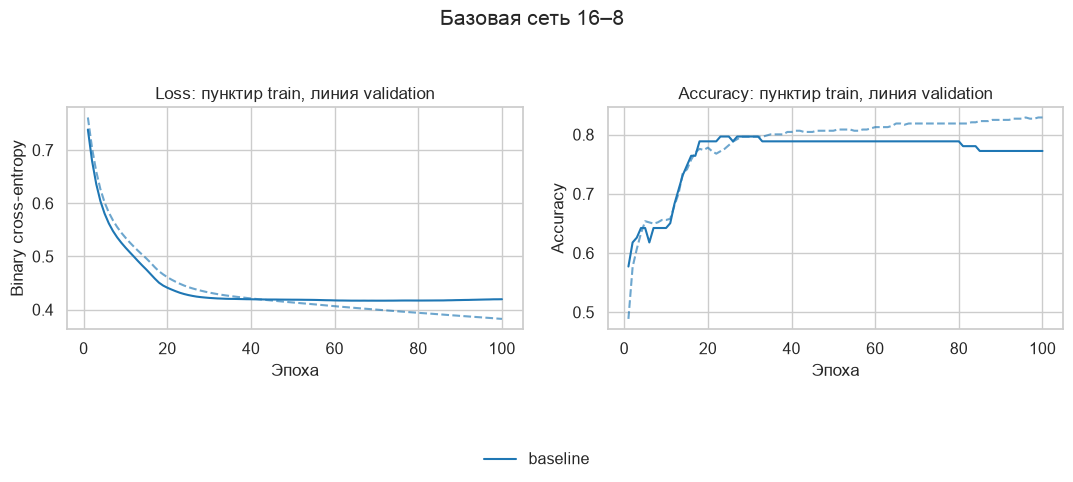

In [29]:
display(run_nn_trial('baseline'))
plot_nn_trials(['baseline'], 'Базовая сеть 16–8')

Базовая сеть за 100 эпох получила train loss 0,381 и validation loss 0,420; validation accuracy равна 0,772. Минимальный validation loss был на 70-й эпохе. На графике train loss продолжает снижаться после этого минимума.

,run,architecture,activation,batch_size,epochs,parameters,training_seconds,train_loss,val_loss,train_accuracy,val_accuracy,val_roc_auc,min_history_val_loss,best_epoch
0,baseline,16-8,relu,32,100,289,4.878411,0.381293,0.419569,0.826884,0.772358,0.874128,0.416833,70
1,epochs_20,16-8,relu,32,20,289,1.565310,0.458271,0.441212,0.775967,0.788618,0.863372,0.441212,20
2,epochs_50,16-8,relu,32,50,289,2.738678,0.412232,0.418670,0.808554,0.788618,0.870930,0.418670,50
3,epochs_200,16-8,relu,32,200,289,8.840095,0.333707,0.444076,0.855397,0.764228,0.864244,0.416833,70


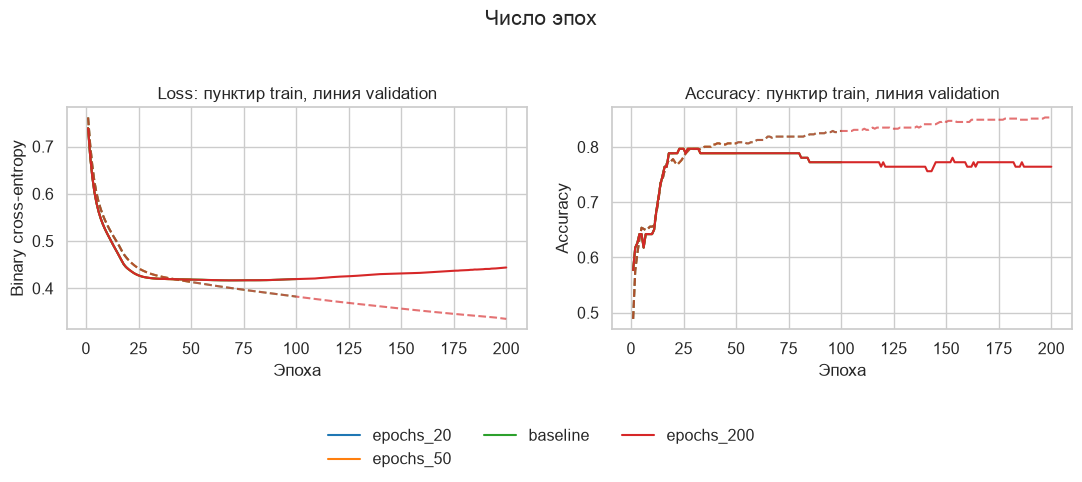

In [30]:
for epochs in [20, 50, 200]:
    run_nn_trial(f'epochs_{epochs}', epochs=epochs)
display(pd.DataFrame(nn_trial_rows).query("run == 'baseline' or run.str.startswith('epochs_')", engine='python'))
plot_nn_trials(['epochs_20', 'epochs_50', 'baseline', 'epochs_200'], 'Число эпох')

После 20, 50, 100 и 200 эпох validation loss равен 0,441, 0,419, 0,420, 0,444. При 200 эпохах train loss снижается до 0,334, а validation loss растёт по сравнению со 100 эпохами. Это признак переобучения на этой validation-части.

,run,architecture,activation,batch_size,epochs,parameters,training_seconds,train_loss,val_loss,train_accuracy,val_accuracy,val_roc_auc,min_history_val_loss,best_epoch
0,baseline,16-8,relu,32,100,289,4.878411,0.381293,0.419569,0.826884,0.772358,0.874128,0.416833,70
4,batch_8,16-8,relu,8,100,289,8.227317,0.334657,0.458291,0.853360,0.764228,0.855523,0.423087,30
5,batch_16,16-8,relu,16,100,289,5.886481,0.358791,0.428013,0.845214,0.764228,0.870930,0.416845,51
6,batch_64,16-8,relu,64,100,289,4.240617,0.400421,0.416172,0.810591,0.788618,0.872384,0.416171,95
7,batch_128,16-8,relu,128,100,289,3.897401,0.419468,0.417611,0.808554,0.788618,0.871512,0.417611,100


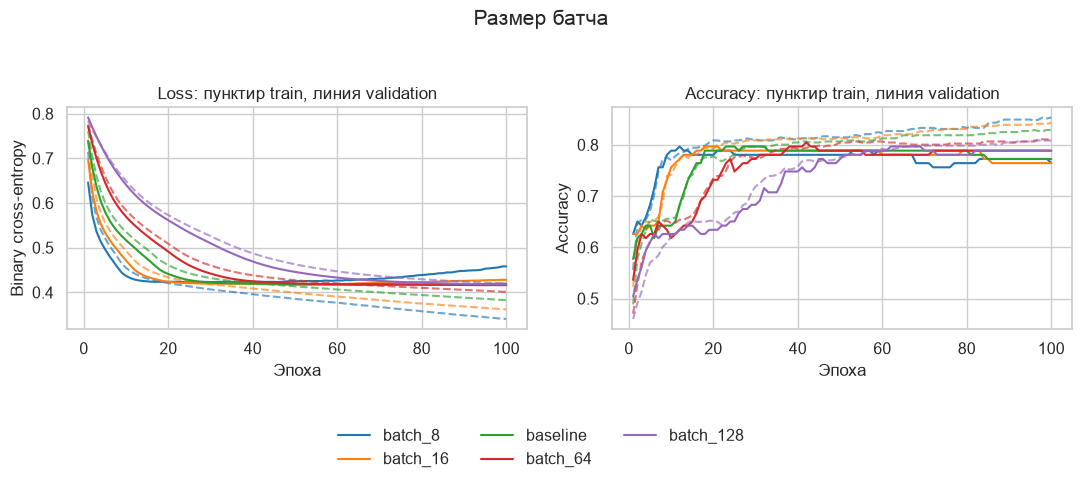

In [31]:
for batch_size in [8, 16, 64, 128]:
    run_nn_trial(f'batch_{batch_size}', batch_size=batch_size)
display(pd.DataFrame(nn_trial_rows).query("run == 'baseline' or run.str.startswith('batch_')", engine='python'))
plot_nn_trials(['batch_8', 'batch_16', 'baseline', 'batch_64', 'batch_128'], 'Размер батча')

Наименьший итоговый validation loss среди размеров батча у batch = 64: 0,416. Для batch = 8 он равен 0,458, для исходного batch = 32 — 0,420. Маленький батч даёт больше обновлений за эпоху; при batch = 8 минимум validation loss был уже на 30-й эпохе.

,run,architecture,activation,batch_size,epochs,parameters,training_seconds,train_loss,val_loss,train_accuracy,val_accuracy,val_roc_auc,min_history_val_loss,best_epoch
0,baseline,16-8,relu,32,100,289,4.878411,0.381293,0.419569,0.826884,0.772358,0.874128,0.416833,70
8,layers_8,8,relu,32,100,81,4.605180,0.431564,0.408978,0.798371,0.764228,0.881977,0.408663,91
9,layers_32,32,relu,32,100,321,4.599599,0.398039,0.419379,0.816701,0.780488,0.869477,0.418518,34
10,layers_32-16,32-16,relu,32,100,833,4.895099,0.312989,0.474265,0.865580,0.788618,0.847965,0.410495,17
11,layers_64-32-16,64-32-16,relu,32,100,3201,5.015322,0.078857,0.729730,0.981670,0.764228,0.823837,0.413519,6
12,layers_128-64,128-64,relu,32,100,9473,4.891418,0.080920,0.633135,0.987780,0.788618,0.834884,0.405302,10


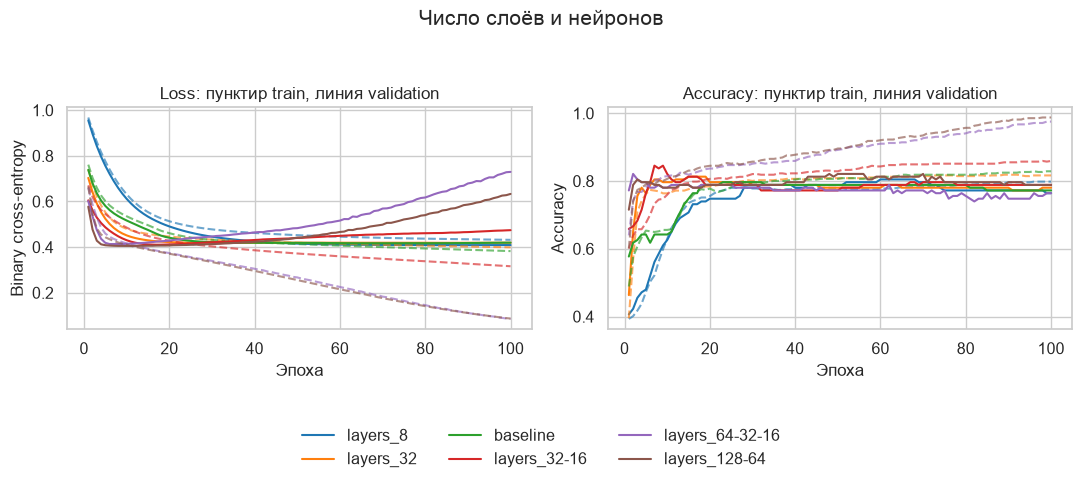

In [32]:
for architecture in [(8,), (32,), (32, 16), (64, 32, 16), (128, 64)]:
    run_nn_trial('layers_' + '-'.join(map(str, architecture)), architecture=architecture)
display(pd.DataFrame(nn_trial_rows).query("run == 'baseline' or run.str.startswith('layers_')", engine='python'))
plot_nn_trials(['layers_8', 'layers_32', 'baseline', 'layers_32-16', 'layers_64-32-16', 'layers_128-64'], 'Число слоёв и нейронов')

Один скрытый слой из 8 нейронов получил validation loss 0,409, тогда как сети 64–32–16 и 128–64 — 0,730 и 0,633. У последних train accuracy выше 0,98, но validation loss заметно хуже. Увеличение числа параметров в этих опытах усилило переобучение.

,run,architecture,activation,batch_size,epochs,parameters,training_seconds,train_loss,val_loss,train_accuracy,val_accuracy,val_roc_auc,min_history_val_loss,best_epoch
0,baseline,16-8,relu,32,100,289,4.878411,0.381293,0.419569,0.826884,0.772358,0.874128,0.416833,70
13,activation_tanh,16-8,tanh,32,100,289,4.789401,0.413949,0.448422,0.814664,0.764228,0.855233,0.431958,24
14,activation_sigmoid,16-8,sigmoid,32,100,289,4.800736,0.457930,0.429046,0.790224,0.796748,0.875581,0.429046,100
15,activation_elu,16-8,elu,32,100,289,4.805708,0.415201,0.431780,0.806517,0.780488,0.865407,0.414427,24
16,activation_linear,16-8,linear,32,100,289,4.841563,0.461367,0.424362,0.792261,0.804878,0.871802,0.423586,23


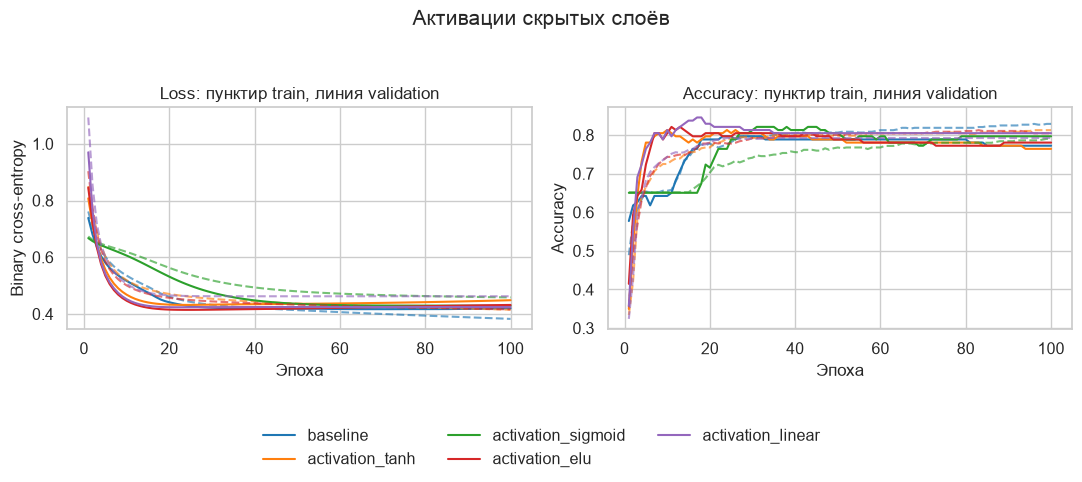

In [33]:
for activation in ['tanh', 'sigmoid', 'elu', 'linear']:
    run_nn_trial(f'activation_{activation}', activation=activation)
display(pd.DataFrame(nn_trial_rows).query("run == 'baseline' or run.str.startswith('activation_')", engine='python'))
plot_nn_trials(['baseline', 'activation_tanh', 'activation_sigmoid', 'activation_elu', 'activation_linear'], 'Активации скрытых слоёв')

Для ReLU validation loss равен 0,420, для linear — 0,424, для sigmoid — 0,429, для tanh — 0,448. ReLU дала наименьший loss среди проверенных активаций. Линейные скрытые слои дают линейное преобразование перед sigmoid, но их близкий результат здесь не доказывает линейную разделимость данных.

,run,architecture,activation,batch_size,epochs,parameters,training_seconds,train_loss,val_loss,train_accuracy,val_accuracy,val_roc_auc,min_history_val_loss,best_epoch
17,early_stopping,16-8,relu,32,90,289,4.409632,0.398855,0.416833,0.818737,0.788618,0.875291,0.416833,70


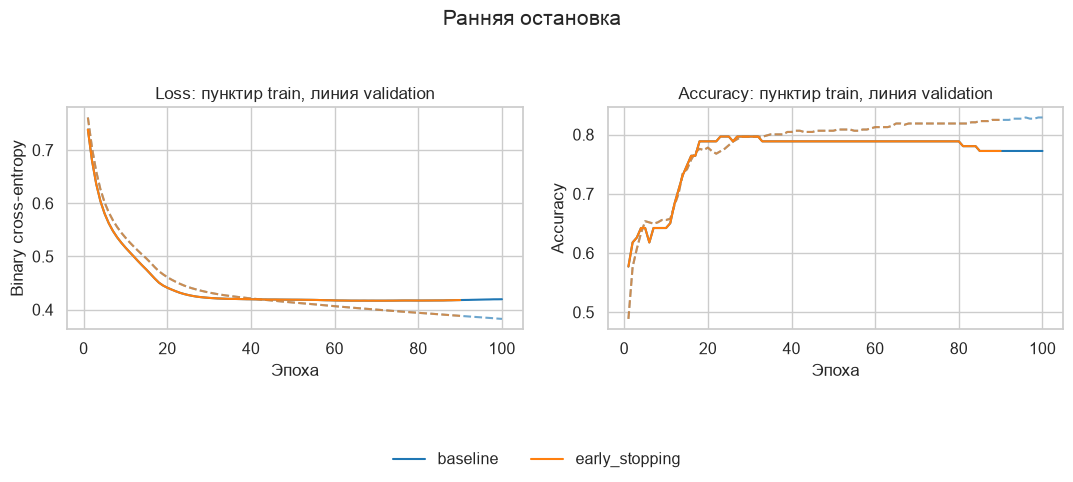

,run,architecture,activation,batch_size,epochs,parameters,training_seconds,train_loss,val_loss,train_accuracy,val_accuracy,val_roc_auc,min_history_val_loss,best_epoch
0,layers_8,8,relu,32,100,81,4.605180,0.431564,0.408978,0.798371,0.764228,0.881977,0.408663,91
1,batch_64,16-8,relu,64,100,289,4.240617,0.400421,0.416172,0.810591,0.788618,0.872384,0.416171,95
2,early_stopping,16-8,relu,32,90,289,4.409632,0.398855,0.416833,0.818737,0.788618,0.875291,0.416833,70
3,batch_128,16-8,relu,128,100,289,3.897401,0.419468,0.417611,0.808554,0.788618,0.871512,0.417611,100
4,epochs_50,16-8,relu,32,50,289,2.738678,0.412232,0.418670,0.808554,0.788618,0.870930,0.418670,50
5,layers_32,32,relu,32,100,321,4.599599,0.398039,0.419379,0.816701,0.780488,0.869477,0.418518,34
6,baseline,16-8,relu,32,100,289,4.878411,0.381293,0.419569,0.826884,0.772358,0.874128,0.416833,70
7,activation_linear,16-8,linear,32,100,289,4.841563,0.461367,0.424362,0.792261,0.804878,0.871802,0.423586,23
8,batch_16,16-8,relu,16,100,289,5.886481,0.358791,0.428013,0.845214,0.764228,0.870930,0.416845,51
9,activation_sigmoid,16-8,sigmoid,32,100,289,4.800736,0.457930,0.429046,0.790224,0.796748,0.875581,0.429046,100


Опытов: 18 | наименьший итоговый validation loss: layers_8
TensorBoard logdir: runtime/logs/20261110-213928


In [34]:
display(run_nn_trial('early_stopping', epochs=200, early_stopping=True))
plot_nn_trials(['baseline', 'early_stopping'], 'Ранняя остановка')
nn_experiments = pd.DataFrame(nn_trial_rows).sort_values('val_loss').reset_index(drop=True)
nn_best_trial_name = str(nn_experiments.iloc[0]['run'])
display(nn_experiments)
print('Опытов:', len(nn_experiments), '| наименьший итоговый validation loss:', nn_best_trial_name)
print('TensorBoard logdir:', LOG_DIR)

### TensorBoard

В интерфейсе открыты baseline и опыт на 200 эпох с train и validation. Показаны accuracy и loss без сглаживания. После 100 эпох train loss продолжает снижаться, а validation loss растёт. Это тот же ход обучения, который показан на графике эксперимента с числом эпох.

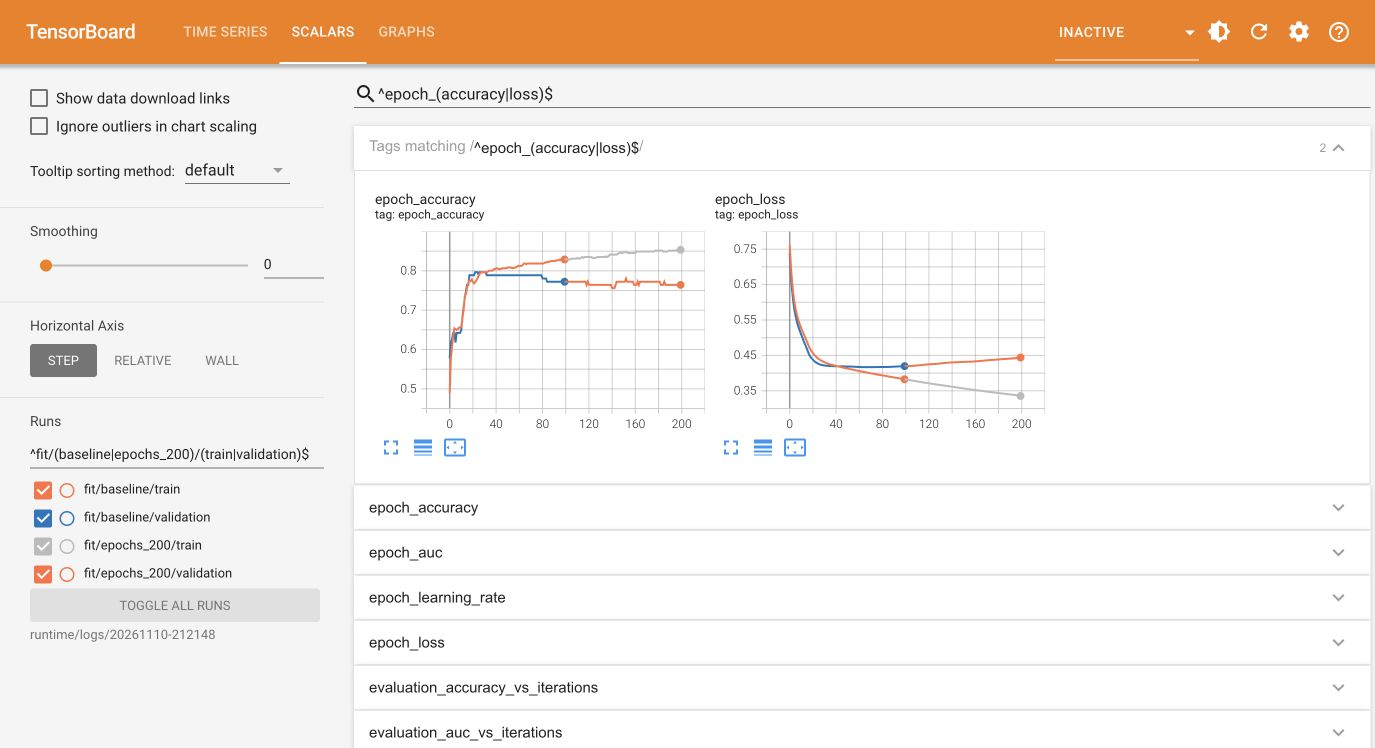

EarlyStopping завершил обучение после 90 эпох и восстановил веса 70-й эпохи. Validation loss восстановленной модели равен 0,417. В таблице 18 обычных опытов; наименьший итоговый validation loss у одного слоя из 8 нейронов (0,409). Test в этих сравнениях не использовался.

## 6. Дополнительное задание: Grid Search с пятью фолдами

Перебираются learning rate 0,01, 0,001 и 0,0001 и архитектуры 16, 32–16, 64–32–16. Для всех сочетаний заданы 100 эпох, batch 32 и ReLU. Выбор делается по средней accuracy пяти валидационных фолдов.

In [35]:
NN_LEARNING_RATES = [0.01, 0.001, 0.0001]
NN_ARCHITECTURES = [(16,), (32, 16), (64, 32, 16)]
nn_cv_histories = {}

def validate_nn_configuration(architecture, learning_rate, run_name):
    rows = []
    histories = []
    for fold, (train_indices, val_indices) in enumerate(cv.split(X_train, y_train), start=1):
        preprocessor = make_nn_preprocessor()
        fold_train = preprocessor.fit_transform(X_train.iloc[train_indices]).astype('float32')
        fold_val = preprocessor.transform(X_train.iloc[val_indices]).astype('float32')
        fold_y_train = y_train.iloc[train_indices]
        fold_y_val = y_train.iloc[val_indices]
        model = make_nn(architecture, learning_rate=learning_rate)
        callback = tf.keras.callbacks.TensorBoard(log_dir=str(LOG_DIR / 'gridsearch' / run_name / f'fold_{fold}'), update_freq='epoch')
        started = time.perf_counter()
        history = model.fit(
            fold_train, fold_y_train, validation_data=(fold_val, fold_y_val),
            epochs=100, batch_size=32, callbacks=[callback], verbose=0
        )
        training_seconds = time.perf_counter() - started
        metrics = model.evaluate(fold_val, fold_y_val, verbose=0, return_dict=True)
        probabilities = model(fold_val, training=False).numpy().ravel()
        rows.append({'configuration': run_name, 'fold': fold,
                     'accuracy': accuracy_score(fold_y_val, probabilities >= 0.5),
                     'loss': metrics['loss'], 'roc_auc': roc_auc_score(fold_y_val, probabilities),
                     'training_seconds': training_seconds})
        histories.append(history.history)
    nn_cv_histories[run_name] = histories
    return rows

nn_cv_rows = []
nn_cv_fold_rows = []
for learning_rate in NN_LEARNING_RATES:
    for architecture in NN_ARCHITECTURES:
        architecture_name = '-'.join(map(str, architecture))
        run_name = f'lr_{learning_rate}_layers_{architecture_name}'
        fold_rows = validate_nn_configuration(architecture, learning_rate, run_name)
        nn_cv_fold_rows.extend(fold_rows)
        fold_table = pd.DataFrame(fold_rows)
        nn_cv_rows.append({
            'configuration': run_name, 'architecture': architecture_name, 'learning_rate': learning_rate,
            'accuracy_mean': fold_table['accuracy'].mean(), 'accuracy_std': fold_table['accuracy'].std(ddof=0),
            'loss_mean': fold_table['loss'].mean(), 'loss_std': fold_table['loss'].std(ddof=0),
            'training_seconds_mean': fold_table['training_seconds'].mean(),
            'training_seconds_std': fold_table['training_seconds'].std(ddof=0),
            'training_seconds_total': fold_table['training_seconds'].sum(),
            'roc_auc_mean': fold_table['roc_auc'].mean(), 'roc_auc_std': fold_table['roc_auc'].std(ddof=0)
        })
        print('Завершено:', run_name, '| accuracy:', round(fold_table['accuracy'].mean(), 4))
nn_cv_results = pd.DataFrame(nn_cv_rows)
nn_cv_folds = pd.DataFrame(nn_cv_fold_rows)
assert len(nn_cv_results) == 9 and len(nn_cv_folds) == 45
assert nn_cv_folds.groupby('configuration')['fold'].nunique().eq(5).all()
display(nn_cv_results.sort_values('accuracy_mean', ascending=False))
display(nn_cv_folds.pivot(index='configuration', columns='fold', values='accuracy'))

,configuration,architecture,learning_rate,accuracy_mean,accuracy_std,loss_mean,loss_std,training_seconds_mean,training_seconds_std,training_seconds_total,roc_auc_mean,roc_auc_std
8,lr_0.0001_layers_64-32-16,64-32-16,0.0001,0.788258,0.014761,0.452242,0.034964,5.883676,0.071693,29.418379,0.854197,0.020117
3,lr_0.001_layers_16,16,0.0010,0.783367,0.014491,0.454854,0.042076,32.320660,33.913615,161.603302,0.852432,0.025169
0,lr_0.01_layers_16,16,0.0100,0.767080,0.027675,0.597086,0.108607,4.646179,0.025352,23.230893,0.808238,0.044315
4,lr_0.001_layers_32-16,32-16,0.0010,0.762228,0.020011,0.537098,0.067100,13.860070,4.720035,69.300348,0.822416,0.034818
7,lr_0.0001_layers_32-16,32-16,0.0001,0.757364,0.026619,0.489316,0.015950,5.929653,0.349157,29.648267,0.825923,0.015670
2,lr_0.01_layers_64-32-16,64-32-16,0.0100,0.731201,0.043203,2.806332,0.405190,5.023563,0.045672,25.117816,0.772398,0.050067
5,lr_0.001_layers_64-32-16,64-32-16,0.0010,0.729628,0.047588,1.172541,0.252650,10.507181,2.754366,52.535904,0.763875,0.052419
6,lr_0.0001_layers_16,16,0.0001,0.721551,0.023219,0.560476,0.020954,6.194148,1.080318,30.970739,0.746283,0.031228
1,lr_0.01_layers_32-16,32-16,0.0100,0.695375,0.038899,2.435645,0.513098,4.817781,0.013633,24.088904,0.737402,0.052797


fold,1,2,3,4,5
configuration,,,,,
lr_0.0001_layers_16,0.731707,0.715447,0.723577,0.682927,0.754098
lr_0.0001_layers_32-16,0.723577,0.747967,0.796748,0.739837,0.778689
lr_0.0001_layers_64-32-16,0.804878,0.764228,0.796748,0.796748,0.778689
lr_0.001_layers_16,0.788618,0.788618,0.804878,0.764228,0.770492
lr_0.001_layers_32-16,0.772358,0.747967,0.788618,0.731707,0.770492
lr_0.001_layers_64-32-16,0.756098,0.747967,0.780488,0.642276,0.721311
lr_0.01_layers_16,0.796748,0.764228,0.796748,0.723577,0.754098
lr_0.01_layers_32-16,0.739837,0.691057,0.739837,0.650407,0.655738
lr_0.01_layers_64-32-16,0.715447,0.731707,0.813008,0.707317,0.688525


Выполнены 9 × 5 = 45 обучений. Средняя accuracy меняется от 0,695 до 0,788. У лучшего сочетания loss равен 0,452, стандартное отклонение accuracy составляет 0,015. Один вызов fit в этой конфигурации занимал в среднем 5,88 с. Замер учитывает только fit. Для сети с 16 нейронами и скоростью обучения 0,001 получено 32,32 ± 33,91 с. Из-за такого разброса по времени нельзя надёжно сравнить скорость конфигураций по одному прогону. Стандартное отклонение accuracy показывает разброс по фолдам.

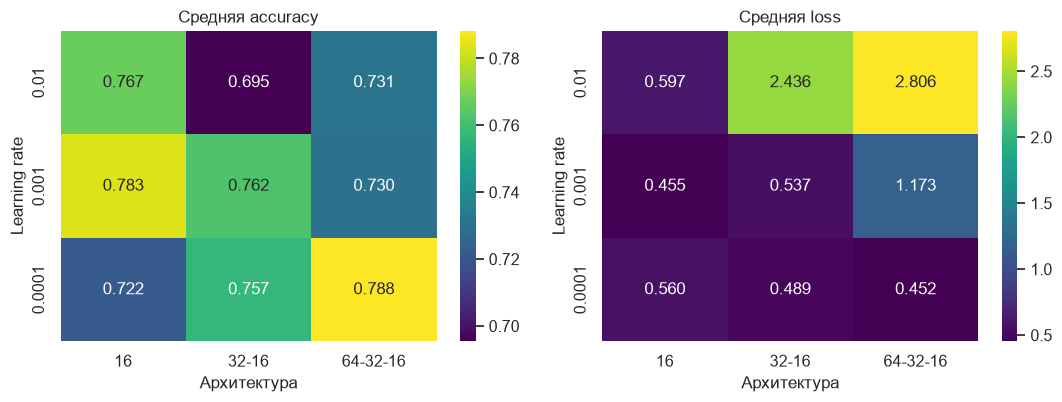

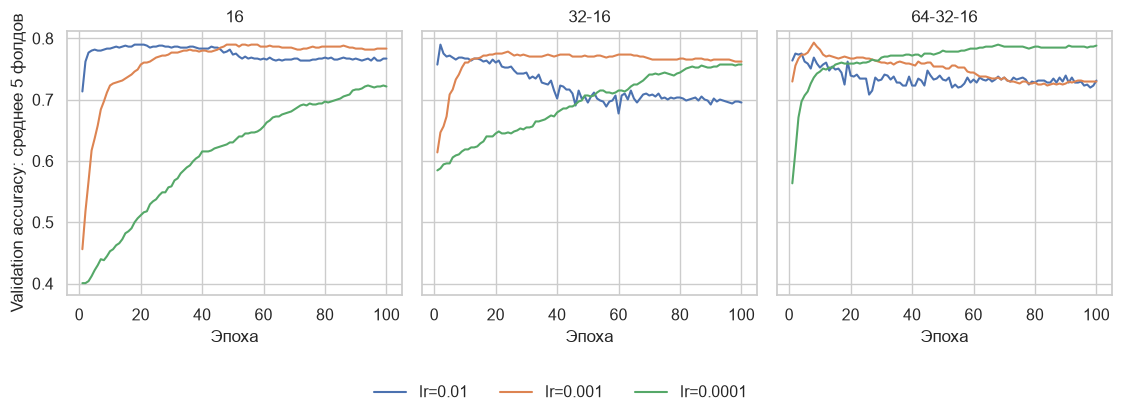

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric, title in zip(axes, ['accuracy_mean', 'loss_mean'], ['Средняя accuracy', 'Средняя loss']):
    matrix = nn_cv_results.pivot(index='learning_rate', columns='architecture', values=metric)
    matrix = matrix.reindex(index=NN_LEARNING_RATES, columns=['16', '32-16', '64-32-16'])
    sns.heatmap(matrix, annot=True, fmt='.3f', cmap='viridis', ax=ax)
    ax.set(xlabel='Архитектура', ylabel='Learning rate', title=title)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.4), sharey=True)
for ax, architecture in zip(axes, NN_ARCHITECTURES):
    architecture_name = '-'.join(map(str, architecture))
    for learning_rate in NN_LEARNING_RATES:
        run_name = f'lr_{learning_rate}_layers_{architecture_name}'
        histories = nn_cv_histories[run_name]
        mean_curve = np.mean([history['val_accuracy'] for history in histories], axis=0)
        ax.plot(np.arange(1, 101), mean_curve, label=f'lr={learning_rate}')
    ax.set(xlabel='Эпоха', title=architecture_name)
axes[0].set_ylabel('Validation accuracy: среднее 5 фолдов')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.11, 1, 0.96))
plt.show()

Для архитектуры 16 лучшая из трёх скоростей — 0,001, для 32–16 — тоже 0,001, для 64–32–16 — 0,0001. При learning rate = 0,01 большие сети имеют средний loss 2,436 и 2,806. Кривые по эпохам помогают сопоставить эти значения с ходом обучения; отдельные train/validation-кривые каждого фолда сохранены в TensorBoard.

In [37]:
nn_baseline_folds = pd.DataFrame(validate_nn_configuration((16, 8), 0.001, 'baseline_16-8_lr_0.001'))
assert len(nn_baseline_folds) == 5
nn_baseline_cv = {
    'accuracy_mean': float(nn_baseline_folds['accuracy'].mean()),
    'accuracy_std': float(nn_baseline_folds['accuracy'].std(ddof=0)),
    'roc_auc_mean': float(nn_baseline_folds['roc_auc'].mean()),
    'roc_auc_std': float(nn_baseline_folds['roc_auc'].std(ddof=0)),
    'loss_mean': float(nn_baseline_folds['loss'].mean()),
    'loss_std': float(nn_baseline_folds['loss'].std(ddof=0)),
    'training_seconds_mean': float(nn_baseline_folds['training_seconds'].mean()),
    'training_seconds_std': float(nn_baseline_folds['training_seconds'].std(ddof=0)),
    'training_seconds_total': float(nn_baseline_folds['training_seconds'].sum())
}
nn_best_row = nn_cv_results.loc[nn_cv_results['accuracy_mean'].idxmax()]
nn_best_architecture = tuple(int(value) for value in nn_best_row['architecture'].split('-'))
nn_best_learning_rate = float(nn_best_row['learning_rate'])
nn_baseline_name = 'Нейросеть baseline 16-8'
nn_best_name = f"Нейросеть Grid Search {nn_best_row['architecture']}, lr={nn_best_learning_rate}"
display(pd.DataFrame([{'model': nn_baseline_name, **nn_baseline_cv},
                      {'model': nn_best_name, **nn_best_row[['accuracy_mean', 'accuracy_std', 'roc_auc_mean', 'roc_auc_std', 'loss_mean', 'loss_std', 'training_seconds_mean', 'training_seconds_std', 'training_seconds_total']].to_dict()}]))
print('Выбор до test:', nn_best_name)

,model,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std,loss_mean,loss_std,training_seconds_mean,training_seconds_std,training_seconds_total
0,Нейросеть baseline 16-8,0.778515,0.011683,0.850472,0.018623,0.466499,0.036126,6.086267,0.454694,30.431334
1,"Нейросеть Grid Search 64-32-16, lr=0.0001",0.788258,0.014761,0.854197,0.020117,0.452242,0.034964,5.883676,0.071693,29.418379


Выбор до test: Нейросеть Grid Search 64-32-16, lr=0.0001


Baseline 16–8 на тех же пяти фолдах получил accuracy 0,7785 и SD 0,0117. Для 64–32–16 с learning rate = 0,0001 значения равны 0,7883 и 0,0148. Прирост средней accuracy составляет 0,0097. Конфигурация выбрана до test; сравнение на тех же фолдах не доказывает, что прирост сохранится на отложенной выборке.

In [38]:
nn_preprocessor = make_nn_preprocessor()
X_nn_full_train = nn_preprocessor.fit_transform(X_train).astype('float32')
final_nets = {}
for name, architecture, learning_rate, log_name in [
    (nn_baseline_name, (16, 8), 0.001, 'baseline'),
    (nn_best_name, nn_best_architecture, nn_best_learning_rate, 'grid_search')
]:
    model = make_nn(architecture, learning_rate=learning_rate)
    model.fit(
        X_nn_full_train, y_train, epochs=100, batch_size=32, verbose=0,
        callbacks=[tf.keras.callbacks.TensorBoard(log_dir=str(LOG_DIR / 'final' / log_name), update_freq='epoch')]
    )
    final_nets[name] = model
print('Финальные сети обучены на строках train:', len(y_train))
print('Модели для итогового сравнения:', list(final_nets))
print('TensorBoard: tensorboard --logdir', LOG_DIR, '--host 127.0.0.1 --port 6006')

Финальные сети обучены на строках train: 614
Модели для итогового сравнения: ['Нейросеть baseline 16-8', 'Нейросеть Grid Search 64-32-16, lr=0.0001']
TensorBoard: tensorboard --logdir runtime/logs/20261110-213928 --host 127.0.0.1 --port 6006


Baseline и выбранная конфигурация обучены на всех 614 train-объектах по 100 эпох. Общая предобработка тоже обучена только на этих строках. Теперь можно переходить к test. Для воспроизведения TensorBoard используется напечатанный путь к логам.

## 7. Итоговая проверка на test

Параметры классических моделей и сетей уже выбраны. Для каждой модели считаются accuracy, precision, recall, F1 и ROC-AUC. Precision, recall и F1 относятся к классу 1. SVM предсказывает класс по знаку `decision_function`; порог 0,5 относится к вероятностям других классификаторов и выходу sigmoid сети.

In [39]:
def positive_score(model, values):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(values)[:, 1]
    return model.decision_function(values)

def metric_row(target, prediction, score):
    return {'accuracy': accuracy_score(target, prediction), 'precision': precision_score(target, prediction, zero_division=0), 'recall': recall_score(target, prediction, zero_division=0), 'f1': f1_score(target, prediction, zero_division=0), 'roc_auc': roc_auc_score(target, score)}

baseline_test, tuned_test, predictions, test_scores = {}, {}, {}, {}
for name in models_default:
    base = models_default[name].fit(X_train, y_train)
    baseline_test[name] = metric_row(y_test, base.predict(X_test), positive_score(base, X_test))
    fitted = searches[name].best_estimator_
    predictions[name] = fitted.predict(X_test)
    test_scores[name] = positive_score(fitted, X_test)
    tuned_test[name] = metric_row(y_test, predictions[name], test_scores[name])
X_test_nn = nn_preprocessor.transform(X_test).astype('float32')
for name, model in final_nets.items():
    test_scores[name] = model(X_test_nn, training=False).numpy().ravel()
    predictions[name] = (test_scores[name] >= 0.5).astype(int)
    tuned_test[name] = metric_row(y_test, predictions[name], test_scores[name])
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
tuned_test['Постоянный класс'] = metric_row(y_test, dummy.predict(X_test), dummy.predict_proba(X_test)[:, 1])
final_table = pd.DataFrame(tuned_test).T
display(final_table.round(4))

,accuracy,precision,recall,f1,roc_auc
GaussianNB,0.7013,0.5667,0.6296,0.5965,0.7644
MultinomialNB,0.6494,0.0000,0.0000,0.0000,0.7674
ComplementNB,0.7338,0.6000,0.7222,0.6555,0.7674
BernoulliNB,0.6948,0.5686,0.5370,0.5524,0.6822
Decision Tree,0.7792,0.7778,0.5185,0.6222,0.8378
LDA,0.7013,0.5870,0.5000,0.5400,0.8080
SVM,0.6948,0.5778,0.4815,0.5253,0.8169
kNN,0.7208,0.6486,0.4444,0.5275,0.8000
Нейросеть baseline 16-8,0.7403,0.6346,0.6111,0.6226,0.8137
"Нейросеть Grid Search 64-32-16, lr=0.0001",0.7208,0.6122,0.5556,0.5825,0.8189


На test у дерева наибольшие accuracy (0,779) и ROC-AUC (0,838). У выбранного по CV SVM они равны 0,695 и 0,817; порядок на test отличается от порядка на CV. ComplementNB получил наибольшие recall (0,722) и F1 (0,655). MultinomialNB предсказывает только класс 0 и по accuracy совпадает с постоянной моделью (0,649).

,ROC-AUC до,ROC-AUC после,F1 до,F1 после
GaussianNB,0.7646,0.7644,0.5965,0.5965
MultinomialNB,0.7674,0.7674,0.0000,0.0000
ComplementNB,0.7674,0.7674,0.6555,0.6555
BernoulliNB,0.7469,0.6822,0.5347,0.5524
Decision Tree,0.6357,0.8378,0.5149,0.6222
LDA,0.8126,0.8080,0.5306,0.5400
SVM,0.7963,0.8169,0.6000,0.5253
kNN,0.7899,0.8000,0.6346,0.5275


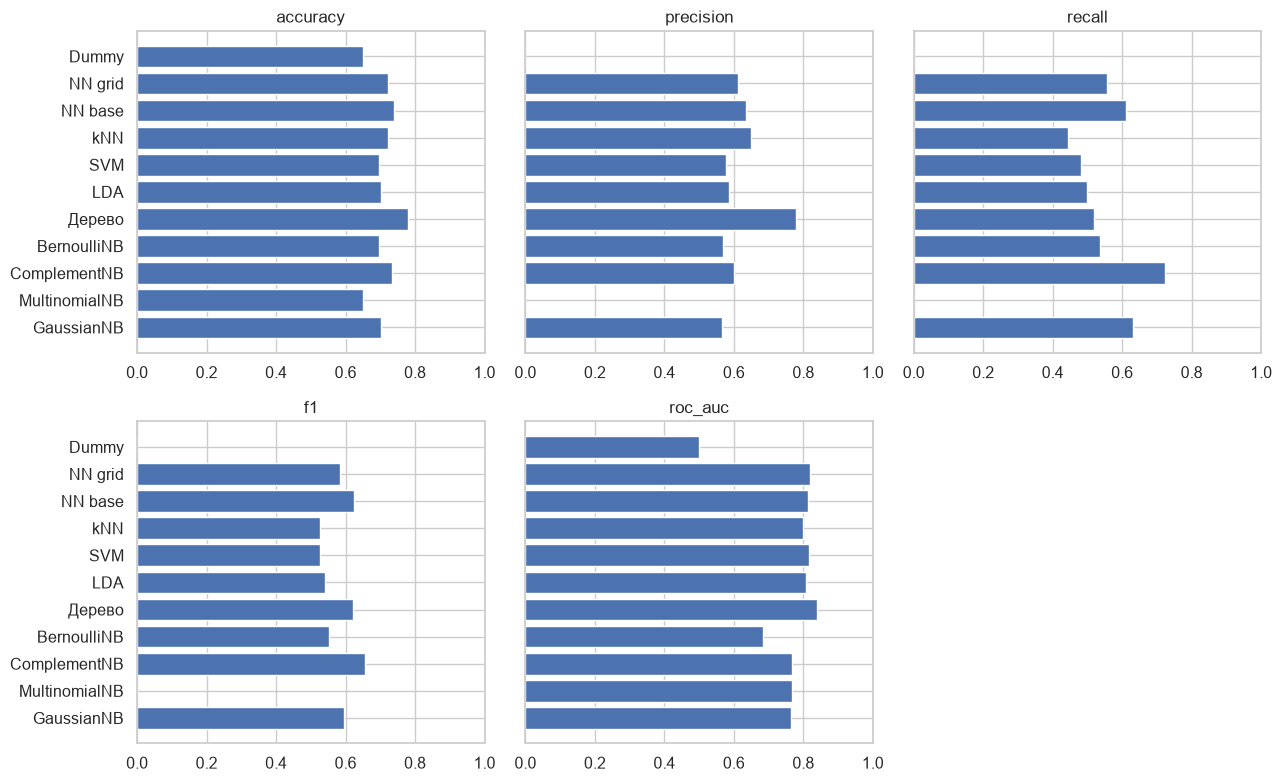

In [40]:
effect = pd.DataFrame({'ROC-AUC до': {name: row['roc_auc'] for name, row in baseline_test.items()}, 'ROC-AUC после': {name: tuned_test[name]['roc_auc'] for name in models_default}, 'F1 до': {name: row['f1'] for name, row in baseline_test.items()}, 'F1 после': {name: tuned_test[name]['f1'] for name in models_default}})
display(effect.round(4))
plot_names = {'Decision Tree': 'Дерево', nn_baseline_name: 'NN base', nn_best_name: 'NN grid', 'Постоянный класс': 'Dummy'}
plot_table = final_table.rename(index=plot_names)
fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharey=True)
for ax, metric in zip(axes.flat, metrics):
    values = plot_table[metric]
    ax.barh(values.index, values)
    ax.set_title(metric)
    ax.set_xlim(0, 1)
axes.flat[-1].axis('off')
fig.tight_layout()
plt.show()

Настройка улучшила test ROC-AUC дерева с 0,636 до 0,838, SVM с 0,796 до 0,817 и kNN с 0,790 до 0,800. У BernoulliNB результат, наоборот, снизился с 0,747 до 0,682. Подбор шёл по CV, поэтому положительный прирост на test не гарантирован. По этой таблице новые параметры не выбираются.

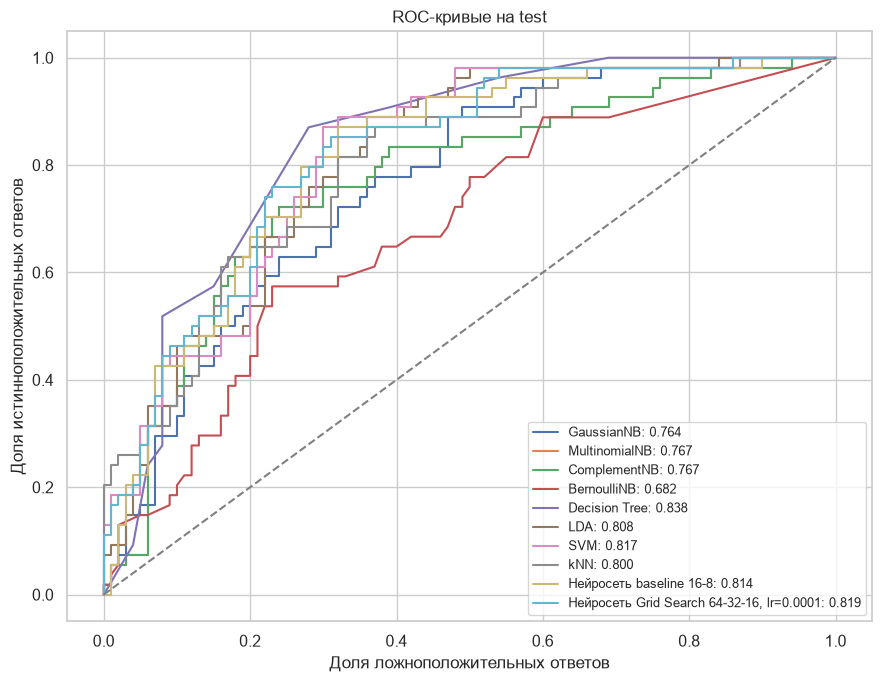

In [41]:
fig, ax = plt.subplots(figsize=(9, 7))
for name, score in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    ax.plot(fpr, tpr, label=f"{name}: {final_table.loc[name, 'roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], linestyle='--', color='grey')
ax.set(xlabel='Доля ложноположительных ответов', ylabel='Доля истинноположительных ответов', title='ROC-кривые на test')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

Test ROC-AUC составляет 0,838 у дерева, 0,819 у настроенной сети и 0,817 у SVM. Кривые построены по непрерывным оценкам; для SVM использован decision_function. AUC оценивает ранжирование, а не качество единственного порога.

,TN,FP,FN,TP
GaussianNB,74,26,20,34
MultinomialNB,100,0,54,0
ComplementNB,74,26,15,39
BernoulliNB,78,22,25,29
Decision Tree,92,8,26,28
LDA,81,19,27,27
SVM,81,19,28,26
kNN,87,13,30,24
Нейросеть baseline 16-8,81,19,21,33
"Нейросеть Grid Search 64-32-16, lr=0.0001",81,19,24,30


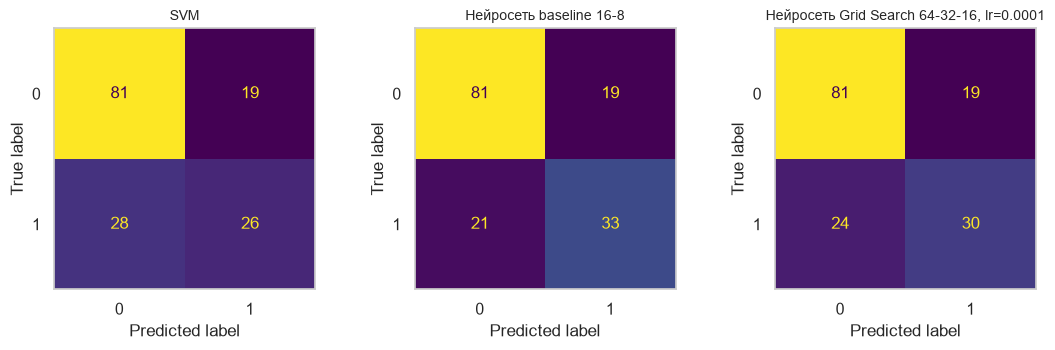

In [42]:
confusions = pd.DataFrame({name: confusion_matrix(y_test, prediction, labels=[0, 1]).ravel() for name, prediction in predictions.items()}, index=['TN', 'FP', 'FN', 'TP']).T
display(confusions)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, name in zip(axes, [chosen_classic, nn_baseline_name, nn_best_name]):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], display_labels=['0', '1'], colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.show()

Дерево правильно распознало 92 объекта класса 0 и 28 объектов класса 1, допустив 8 FP и 26 FN. У baseline-сети 81 TN, 19 FP, 21 FN и 33 TP. Матрицы показывают разные соотношения ошибок; этот учебный эксперимент не используется для выбора медицинских решений.

In [43]:
nn_comparison = final_table.loc[[nn_baseline_name, nn_best_name]].copy()
display(nn_comparison.round(4))
print('Разница test accuracy: Grid Search минус baseline =', round(nn_comparison.loc[nn_best_name, 'accuracy'] - nn_comparison.loc[nn_baseline_name, 'accuracy'], 4))
result = {'data_sha256': hashlib.sha256(Path('diabetes.csv').read_bytes()).hexdigest(), 'split': {'train': len(X_train), 'test': len(X_test)}, 'default_cv': default_cv.reset_index().to_dict(orient='records'), 'tuning': tuning.reset_index().to_dict(orient='records'), 'chosen_classic': chosen_classic, 'test': final_table.reset_index(names='Модель').to_dict(orient='records'), 'baseline_test': baseline_test, 'nn_experiments': nn_experiments.reset_index().to_dict(orient='records'), 'nn_cv': nn_cv_results.reset_index().to_dict(orient='records'), 'nn_baseline_cv': nn_baseline_cv, 'nn_baseline_name': nn_baseline_name, 'nn_best_name': nn_best_name, 'log_dir': str(LOG_DIR)}
Path('runtime/results.json').write_text(json.dumps(result, ensure_ascii=False, indent=2, default=str))

,accuracy,precision,recall,f1,roc_auc
Нейросеть baseline 16-8,0.7403,0.6346,0.6111,0.6226,0.8137
"Нейросеть Grid Search 64-32-16, lr=0.0001",0.7208,0.6122,0.5556,0.5825,0.8189


Разница test accuracy: Grid Search минус baseline = -0.0195


22494

Сеть после Grid Search получила test accuracy 0,7208, baseline — 0,7403. Разница -0,0195 соответствует трём объектам из 154. Прирост CV accuracy не сохранился на test. При этом test ROC-AUC настроенной сети немного выше: 0,8189 против 0,8137.

## 8. Выводы

1. Использован Pima Indians Diabetes: 768 объектов, восемь признаков, классы 500/268. Нули в пяти показателях заменены пропусками; заполнение медианой и масштабирование обучались внутри train и каждого CV-фолда.
2. Среди классических моделей по CV ROC-AUC выбран SVM с RBF, C = 100 и gamma = 0,001 (0,8464). Наибольший прирост от настройки получили дерево и kNN. Из вариантов Байеса лучший CV ROC-AUC у GaussianNB.
3. На test дерево показало accuracy 0,7792 и ROC-AUC 0,8378. Это лучший результат этого тестового сравнения, но модель по test заново не выбиралась. ComplementNB чаще находил класс 1 и получил наибольший F1 (0,6555).
4. В 18 опытах TensorFlow большие сети и длительное обучение могли уменьшать train loss одновременно с ростом validation loss. Ранняя остановка вернула веса 70-й эпохи; результаты train и validation записаны в TensorBoard.
5. Дополнительный Grid Search проверил девять сочетаний на пяти фолдах. Выбрана сеть 64–32–16 с learning rate = 0,0001: CV accuracy 0,7883 против 0,7785 у baseline. На test её accuracy ниже baseline, поэтому преимуществом настройки в этом запуске нельзя считать прирост test accuracy.
6. Метрики и ранги относятся к этому набору, разбиению и окружению. Вывод о превосходстве на других данных потребовал бы отдельной проверки.

## Источники

1. Буркина М., Губко П., Горчаков А. Метрики классификации и регрессии // Учебник по машинному обучению. – URL: https://contest.yandex.ru/tracks/ml/model-evaluation/classification-and-regression-metrics (дата обращения: 10.11.2026).

2. Дополнительное задание к лабораторной работе 2. Классификация с кросс-валидацией : методические указания // Системы искусственного интеллекта и машинное обучение : электронный курс НГТУ. – URL: https://dispace.nstu.ru/course/965/33533/84292 (дата обращения: 10.11.2026).

3. Елистратова Е. Кросс-валидация // Учебник по машинному обучению. – URL: https://contest.yandex.ru/tracks/ml/model-evaluation/cross-validation (дата обращения: 10.11.2026).

4. Елистратова Е. Подбор гиперпараметров // Учебник по машинному обучению. – URL: https://contest.yandex.ru/tracks/ml/model-evaluation/hyperparameter-tuning (дата обращения: 10.11.2026).

5. Лабораторная работа 2. Классификация. Нейронные сети : методические указания // Системы искусственного интеллекта и машинное обучение : электронный курс НГТУ. – URL: https://dispace.nstu.ru/course/965/9023/23597 (дата обращения: 10.11.2026).

6. Синицин Ф., Нейчев Р. Первое знакомство с полносвязными нейросетями // Учебник по машинному обучению. – URL: https://contest.yandex.ru/tracks/ml/deep-learning-introduction/fully-connected-neural-networks (дата обращения: 10.11.2026).

7. Синицин Ф. Решающие деревья // Учебник по машинному обучению. – URL: https://contest.yandex.ru/tracks/ml/supervised-learning/decision-trees (дата обращения: 10.11.2026).

8. diabetes (Pima Indians Diabetes Database), версия 1 : набор данных № 37 // OpenML. – URL: https://www.openml.org/d/37 (дата обращения: 10.11.2026).

9. scikit-learn: machine learning in Python : документация. – URL: https://scikit-learn.org/stable/ (дата обращения: 10.11.2026).

10. Smith J. W., Everhart J. E., Dickson W. C., Knowler W. C., Johannes R. S. Using the ADAP learning algorithm to forecast the onset of diabetes mellitus // Proceedings of the Annual Symposium on Computer Application in Medical Care. – 1988. – P. 261–265. – URL: https://pmc.ncbi.nlm.nih.gov/articles/PMC2245318/ (дата обращения: 10.11.2026).

11. TensorBoard: TensorFlow's visualization toolkit : документация. – URL: https://www.tensorflow.org/tensorboard (дата обращения: 10.11.2026).

12. TensorFlow. Keras: The high-level API for TensorFlow : документация. – URL: https://www.tensorflow.org/guide/keras (дата обращения: 10.11.2026).